# Chapter 9: Travel

Checks [chapter 9](../../book/09-travel.md). The model is **linear in its weights**: its outputs on the
data are `matrix @ weights`. The stand-in is a Fourier series with fixed frequencies whose sine and
cosine coefficients are the weights (linear), fitted to 20 points. The features are scaled by `sqrt(2)`
so that `squared_length`, the squared length of a row of the matrix, is about the number of weights.
Everything is NumPy in float64, seeded. These are measurements, not proofs: the proofs are in
`LinearModel.lean` and `ExchangeRate.lean`.

The **travel** is the distance from the start weights to the nearest weights that fit every label. For a
matrix of full row rank it is `norm(pinv(matrix) @ residual)`. Run every cell, top to bottom. A failed check
stops the notebook.

In [1]:
import sys
sys.path.append("../part1")

import numpy as np
from common import use_style, save_figure, report, NEAREST, VERTICAL, BOUND, MODEL, BEFORE
import matplotlib.pyplot as plt

use_style()
NUM_POINTS = 20
SEED = 9


def build_fourier_matrix(inputs, num_weights):
    """Constant, then sin(k x) and cos(k x) for k = 1, 2, ..., each scaled by sqrt(2)."""
    columns = [np.ones_like(inputs)]
    for frequency in range(1, (num_weights - 1) // 2 + 1):
        columns.append(np.sqrt(2) * np.sin(frequency * inputs))
        columns.append(np.sqrt(2) * np.cos(frequency * inputs))
    return np.stack(columns, axis=1)


def get_residual(matrix, labels, weights):
    return labels - matrix @ weights


def measure_travel(matrix, labels, start_weights):
    """Distance from the start to the nearest fit, or infinity when no weights fit."""
    residual = get_residual(matrix, labels, start_weights)
    step = np.linalg.pinv(matrix) @ residual
    left_over = np.linalg.norm(residual - matrix @ step)
    if left_over > 1e-8 * max(1.0, np.linalg.norm(residual)):
        return np.inf
    return float(np.linalg.norm(step))

## Claim 1: on the straight path to a fit, the error shrinks in proportion (`residual_along`)

Take a random matrix with 25 weights on 20 points, random labels and a random start. The nearest fit is
`start + pinv(matrix) @ residual`. At each fraction `f` of the path the residual must equal `(1 - f)` times the
residual at the start, as vectors, not only in size. The check also confirms the end really is a fit, so the
hypothesis of the theorem holds. A point off the straight path is the control: it must break the proportion.

[PASS] the end of the path is a fit
[PASS] residual on the path = (1 - fraction) * residual at the start, for 31 fractions  (largest entry gap 6.5e-14)
[PASS] half way along, half the error is gone  (ratio 0.500000)
[PASS] a point off the straight path breaks the proportion (the check can fail)  (gap 2.81)
wrote book/figures/09-straight-path.png


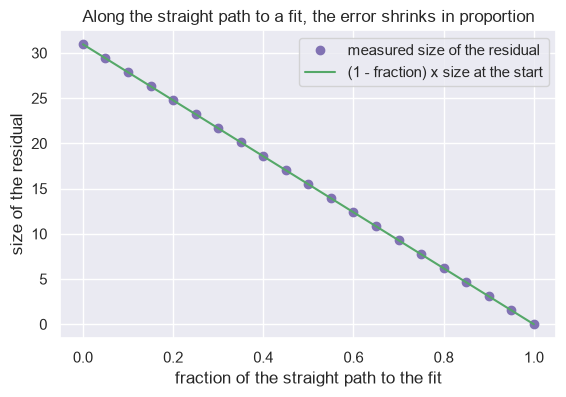

In [2]:
generator = np.random.default_rng(SEED)
matrix = generator.standard_normal((NUM_POINTS, 25))
labels = generator.standard_normal(NUM_POINTS)
start_weights = generator.standard_normal(25)
end_weights = start_weights + np.linalg.pinv(matrix) @ get_residual(matrix, labels, start_weights)
report("the end of the path is a fit", np.allclose(matrix @ end_weights, labels, atol=1e-9))

residual_at_start = get_residual(matrix, labels, start_weights)
fractions = np.linspace(0, 1.5, 31)       # past the end too: the identity is linear in the fraction
worst_gap = 0.0
sizes = []
for fraction in fractions:
    weights_on_path = (1 - fraction) * start_weights + fraction * end_weights
    residual_on_path = get_residual(matrix, labels, weights_on_path)
    sizes.append(np.linalg.norm(residual_on_path))
    worst_gap = max(worst_gap, np.abs(residual_on_path - (1 - fraction) * residual_at_start).max())
report("residual on the path = (1 - fraction) * residual at the start, for 31 fractions",
       worst_gap < 1e-9, f"largest entry gap {worst_gap:.1e}")

half_size = np.linalg.norm(get_residual(matrix, labels, 0.5 * (start_weights + end_weights)))
report("half way along, half the error is gone", abs(half_size / np.linalg.norm(residual_at_start) - 0.5) < 1e-9,
       f"ratio {half_size / np.linalg.norm(residual_at_start):.6f}")

bent_weights = 0.5 * (start_weights + end_weights) + 0.3 * generator.standard_normal(25)
bent_gap = np.abs(get_residual(matrix, labels, bent_weights) - 0.5 * residual_at_start).max()
report("a point off the straight path breaks the proportion (the check can fail)", bent_gap > 1e-3,
       f"gap {bent_gap:.2f}")

on_path = fractions <= 1
figure, axis = plt.subplots(figsize=(6.4, 4))
axis.plot(fractions[on_path], np.array(sizes)[on_path], "o", color=MODEL, label="measured size of the residual")
axis.plot(fractions[on_path], (1 - fractions[on_path]) * np.linalg.norm(residual_at_start), "-",
          color=BOUND, label="(1 - fraction) x size at the start")
axis.set_xlabel("fraction of the straight path to the fit")
axis.set_ylabel("size of the residual")
axis.set_title("Along the straight path to a fit, the error shrinks in proportion")
axis.legend()
save_figure(figure, "09-straight-path")
plt.show()

## Claim 2: adding weights never moves the nearest fit further away (`travel_coprod_le`)

Start with 25 weights on 20 points. Add 1, 5, 20 and 100 extra random columns, with the new weights starting at zero
(as the theorem has it; a nonzero start would also change the residual at the start). The theorem says the travel of the bigger model is at most the travel of the smaller one.
This is an inequality, so it is checked over 200 random draws times 4 sizes. The control: a *fresh* model of
the bigger size (new random columns that do not contain the old ones) has no such guarantee, and sometimes
travels further than the old model. That shows the check can fail when the models are not nested.

In [3]:
generator = np.random.default_rng(SEED + 1)
violations = 0
trials = 0
strictly_smaller = 0
fresh_larger = 0
for trial in range(200):
    base_matrix = generator.standard_normal((NUM_POINTS, 25))
    labels = generator.standard_normal(NUM_POINTS)
    base_start = generator.standard_normal(25)
    base_travel = measure_travel(base_matrix, labels, base_start)
    for extra in (1, 5, 20, 100):
        extra_matrix = generator.standard_normal((NUM_POINTS, extra))
        extra_start = np.zeros(extra)         # the theorem starts the new weights at zero
        big_travel = measure_travel(np.hstack([base_matrix, extra_matrix]), labels,
                                    np.concatenate([base_start, extra_start]))
        trials += 1
        violations += big_travel > base_travel + 1e-9
        strictly_smaller += big_travel < base_travel - 1e-9
        fresh_matrix = generator.standard_normal((NUM_POINTS, 25 + extra))
        fresh_larger += measure_travel(fresh_matrix, labels, generator.standard_normal(25 + extra)) > base_travel
report("travel(bigger model) <= travel(smaller model) in all 800 trials", violations == 0,
       f"{violations} violations; strictly smaller in {strictly_smaller} of {trials}")
report("without nesting the order is not guaranteed (control: fresh bigger models sometimes travel further)",
       fresh_larger > 0, f"{fresh_larger} of {trials}")

[PASS] travel(bigger model) <= travel(smaller model) in all 800 trials  (0 violations; strictly smaller in 800 of 800)
[PASS] without nesting the order is not guaranteed (control: fresh bigger models sometimes travel further)  (301 of 800)


True

## Claim 3: with tight features, travel = residual size / sqrt(squared_length) (`travel_eq`)

Tight features: `matrix @ matrix.T = squared_length * identity` (rows at right angles, each of squared length
`squared_length`). First the chapter's hand example: one data point, `m` features all equal to 1, label 1, start at 0.
The travel must be `1 / sqrt(m)`: 0.5 for 4 features and 0.1 for 100. Then random tight examples: 20 rows
built from the orthonormal rows of a random QR factorisation, scaled by `sqrt(squared_length)`, with a random
start and random labels. The travel from the pseudo-inverse is compared with the formula, and a second route
checks that no other fit, found by adding random null-space moves to the nearest one, is nearer.

In [4]:
for num_features, expected in ((4, 0.5), (100, 0.1)):
    matrix = np.ones((1, num_features))
    travel = measure_travel(matrix, np.array([1.0]), np.zeros(num_features))
    report(f"hand example, {num_features} features: travel = 1 / sqrt({num_features}) = {expected}",
           abs(travel - expected) < 1e-12 and abs(travel - 1 / np.sqrt(num_features)) < 1e-12, f"measured {travel:.6f}")
    cheapest_move = np.full(num_features, 1 / num_features)
    report(f"  and adding 1 / {num_features} to every weight is that move",
           abs(np.linalg.norm(cheapest_move) - travel) < 1e-12)

generator = np.random.default_rng(SEED + 2)
for num_weights, squared_length in ((40, 7.0), (60, 25.0), (300, 0.5)):
    orthonormal, _ = np.linalg.qr(generator.standard_normal((num_weights, NUM_POINTS)))
    matrix = np.sqrt(squared_length) * orthonormal.T
    report(f"random example ({num_weights} weights, squared_length {squared_length}) is tight",
           np.allclose(matrix @ matrix.T, squared_length * np.eye(NUM_POINTS)))
    labels = generator.standard_normal(NUM_POINTS)
    start_weights = generator.standard_normal(num_weights)
    residual_size = np.linalg.norm(get_residual(matrix, labels, start_weights))
    travel = measure_travel(matrix, labels, start_weights)
    predicted = residual_size / np.sqrt(squared_length)

    fit = start_weights + np.linalg.pinv(matrix) @ get_residual(matrix, labels, start_weights)
    null_basis = np.linalg.svd(matrix)[2][NUM_POINTS:]
    nearest_other = min(
        np.linalg.norm(fit + null_basis.T @ (generator.standard_normal(num_weights - NUM_POINTS) * scale) - start_weights)
        for scale in (1e-3, 1e-1, 1.0) for _ in range(200))
    report(f"  travel = residual_size / sqrt(squared_length): {travel:.6f} vs {predicted:.6f}; no sampled fit is nearer",
           abs(travel - predicted) < 1e-10 and nearest_other >= travel - 1e-12)

# Control: features that are not tight break the formula.
loose_matrix = generator.standard_normal((NUM_POINTS, 40)) * np.linspace(0.2, 3, 40)
loose_start = generator.standard_normal(40)
loose_labels = generator.standard_normal(NUM_POINTS)
loose_size = np.linalg.norm(get_residual(loose_matrix, loose_labels, loose_start))
loose_guess = loose_size / np.sqrt(np.mean((loose_matrix ** 2).sum(axis=1)))
loose_travel = measure_travel(loose_matrix, loose_labels, loose_start)
report("control: for loose features the formula is off (the check can fail)",
       abs(loose_travel - loose_guess) / loose_travel > 0.05, f"travel {loose_travel:.3f}, formula {loose_guess:.3f}")

[PASS] hand example, 4 features: travel = 1 / sqrt(4) = 0.5  (measured 0.500000)
[PASS]   and adding 1 / 4 to every weight is that move
[PASS] hand example, 100 features: travel = 1 / sqrt(100) = 0.1  (measured 0.100000)
[PASS]   and adding 1 / 100 to every weight is that move
[PASS] random example (40 weights, squared_length 7.0) is tight
[PASS]   travel = residual_size / sqrt(squared_length): 3.951062 vs 3.951062; no sampled fit is nearer
[PASS] random example (60 weights, squared_length 25.0) is tight
[PASS]   travel = residual_size / sqrt(squared_length): 5.369111 vs 5.369111; no sampled fit is nearer
[PASS] random example (300 weights, squared_length 0.5) is tight
[PASS]   travel = residual_size / sqrt(squared_length): 7.599183 vs 7.599183; no sampled fit is nearer
[PASS] control: for loose features the formula is off (the check can fail)  (travel 4.656, formula 3.655)


True

## Claim 4: the sweep over Fourier terms

20 random inputs in `[0, 2 pi]`, labels from a standard normal, a random start with `weights ~ N(0, 1 / n)` so the
output has the same spread at every size. Loss is `0.5 * mean(residual ** 2)`. For each number of weights `n`
(9, 21, 25, 65, 129, 513) the cell records the loss at the start, the travel, `squared_length`, the exchange-rate
prediction `residual_size / sqrt(squared_length)`, and the number of gradient-descent steps to reach loss
`1e-3` with step size `1 / L`, where `L` is the largest curvature. These step counts reach 10^8, so they are
computed exactly from the singular values: along a direction with singular value `s`, one step multiplies the
residual by `1 - s^2 / s_max^2`. The closed form is checked against real gradient descent where that is short.
The first table is a single seed (the chapter's form); the second is the median of 40 seeds, since one draw can
be unlucky.

In [5]:
LOSS_TARGET = 1e-3
SIZES = (9, 21, 25, 65, 129, 513)


def count_steps_to_loss(matrix, residual, loss_target=LOSS_TARGET):
    """Gradient-descent steps (step size 1 / largest curvature) until 0.5 * mean(residual ** 2) <= loss_target."""
    left, singular_values, _ = np.linalg.svd(matrix, full_matrices=False)
    rank = int((singular_values > 1e-9 * singular_values[0]).sum())
    components = left[:, :rank].T @ residual
    unreachable = residual - left[:, :rank] @ components
    shrink = 1.0 - (singular_values[:rank] / singular_values[0]) ** 2

    def loss_after(steps):
        return 0.5 * (np.sum((components * shrink ** steps) ** 2) + unreachable @ unreachable) / len(residual)

    if loss_after(0) <= loss_target:
        return 0
    if loss_after(10 ** 12) > loss_target:
        return np.inf
    low, high = 0, 10 ** 12
    while high - low > 1:
        middle = (low + high) // 2
        low, high = (middle, high) if loss_after(middle) > loss_target else (low, middle)
    return high


def run_gradient_descent(matrix, labels, start_weights, loss_target=LOSS_TARGET, max_steps=100000):
    step_size = 1.0 / (np.linalg.norm(matrix, 2) ** 2 / len(labels))
    weights = start_weights.copy()
    for step in range(max_steps + 1):
        residual = get_residual(matrix, labels, weights)
        if 0.5 * np.mean(residual ** 2) <= loss_target:
            return step
        weights = weights + step_size * matrix.T @ residual / len(labels)
    return np.inf


def measure_row(seed, num_weights, num_inputs=NUM_POINTS):
    generator = np.random.default_rng(seed)
    inputs = np.sort(generator.uniform(0, 2 * np.pi, num_inputs))
    labels = generator.standard_normal(num_inputs)
    start_weights = generator.standard_normal(num_weights) / np.sqrt(num_weights)
    matrix = build_fourier_matrix(inputs, num_weights)
    residual = get_residual(matrix, labels, start_weights)
    squared_length = float(np.mean((matrix ** 2).sum(axis=1)))
    travel = measure_travel(matrix, labels, start_weights)
    return {"num_weights": num_weights, "loss": 0.5 * float(np.mean(residual ** 2)),
            "travel": travel, "squared_length": squared_length,
            "predicted": float(np.linalg.norm(residual) / np.sqrt(squared_length)),
            "steps": count_steps_to_loss(matrix, residual), "matrix": matrix, "labels": labels,
            "start_weights": start_weights}


single_rows = [measure_row(SEED, size) for size in SIZES]
print(f"{'weights':>8} {'loss0':>7} {'travel':>10} {'predicted':>10} {'sq_len':>7} {'steps':>14}")
for row in single_rows:
    print(f"{row['num_weights']:>8} {row['loss']:>7.2f} {row['travel']:>10.3g} {row['predicted']:>10.3g} "
          f"{row['squared_length']:>7.1f} {row['steps']:>14.6g}")

for row in single_rows:
    if 0 < row["steps"] <= 20000:
        real_steps = run_gradient_descent(row["matrix"], row["labels"], row["start_weights"])
        report(f"{row['num_weights']} weights: closed-form step count equals real gradient descent",
               real_steps == row["steps"], f"{real_steps} vs {row['steps']}")

 weights   loss0     travel  predicted  sq_len          steps
       9    0.98        inf       2.08     9.0            inf
      21    0.86   7.73e+03       1.28    21.0    5.90051e+09
      25    0.92        183       1.21    25.0    4.15343e+06
      65    0.89      0.758      0.741    65.0             13
     129    1.46      0.643      0.673   129.0              6
     513    0.90      0.265      0.265   513.0              3
[PASS] 65 weights: closed-form step count equals real gradient descent  (13 vs 13)
[PASS] 129 weights: closed-form step count equals real gradient descent  (6 vs 6)
[PASS] 513 weights: closed-form step count equals real gradient descent  (3 vs 3)


In [6]:
many_rows = {size: [measure_row(seed, size) for seed in range(40)] for size in SIZES}
print(f"{'weights':>8} {'loss0 med':>10} {'travel med':>11} {'steps med':>14} {'no fit':>7}")
medians = {}
for size in SIZES:
    rows = many_rows[size]
    medians[size] = {"loss": np.median([row["loss"] for row in rows]),
                     "travel": np.median([row["travel"] for row in rows]),
                     "steps": np.median([row["steps"] for row in rows])}
    print(f"{size:>8} {medians[size]['loss']:>10.2f} {medians[size]['travel']:>11.3g} {medians[size]['steps']:>14.6g} "
          f"{sum(row['travel'] == np.inf for row in rows):>7}")

report("9 weights cannot fit 20 points (no fit, steps never)",
       all(row["travel"] == np.inf and row["steps"] == np.inf for row in many_rows[9]))
fitting_sizes = SIZES[1:]
loss_values = [medians[size]["loss"] for size in fitting_sizes]
report("the loss at the start stays level: medians within a factor 2 across all sizes",
       max(loss_values) < 2 * min(loss_values), f"medians {min(loss_values):.2f} to {max(loss_values):.2f}")
travel_values = [medians[size]["travel"] for size in fitting_sizes]
step_values = [medians[size]["steps"] for size in fitting_sizes]
report("median travel falls at every size from 21 to 513 weights",
       all(later < earlier for earlier, later in zip(travel_values, travel_values[1:])), str([f"{v:.3g}" for v in travel_values]))
report("median gradient-descent steps fall at every size from 21 to 513 weights",
       all(later < earlier for earlier, later in zip(step_values, step_values[1:])), str([f"{v:.3g}" for v in step_values]))
report("travel falls by a factor over 100 and steps by a factor over 1000 from 21 to 513 weights",
       travel_values[0] / travel_values[-1] > 100 and step_values[0] / step_values[-1] > 1000,
       f"x{travel_values[0] / travel_values[-1]:.0f} and x{step_values[0] / step_values[-1]:.0f}")

generator = np.random.default_rng(SEED + 3)
inputs = np.sort(generator.uniform(0, 2 * np.pi, NUM_POINTS))
labels = generator.standard_normal(NUM_POINTS)
base_start = generator.standard_normal(21) / np.sqrt(21)
nested = [measure_travel(build_fourier_matrix(inputs, size), labels, np.concatenate([base_start, np.zeros(size - 21)]))
          for size in SIZES[1:]]
report("nested Fourier models (the 21 old weights keep their start, new ones start at zero): travel never rises with size",
       all(later <= earlier + 1e-9 for earlier, later in zip(nested, nested[1:])), str([f"{v:.3g}" for v in nested]))

for size in (129, 513):
    ratios = [row["travel"] / row["predicted"] for row in many_rows[size]]
    print(f"{size} weights: travel / predicted, median {np.median(ratios):.2f}, range {min(ratios):.2f} to {max(ratios):.2f}")
report("at 513 weights the exchange rate predicts the travel within 10 percent (median)",
       abs(np.median([row["travel"] / row["predicted"] for row in many_rows[513]]) - 1) < 0.10)

 weights  loss0 med  travel med      steps med  no fit
       9       0.91         inf            inf      40
      21       1.01    1.29e+03    2.45592e+08       0
      25       1.02        86.4         720133       0
      65       0.89        1.54          386.5       0
     129       0.89       0.696           41.5       0
     513       0.92       0.272              4       0
[PASS] 9 weights cannot fit 20 points (no fit, steps never)
[PASS] the loss at the start stays level: medians within a factor 2 across all sizes  (medians 0.89 to 1.02)
[PASS] median travel falls at every size from 21 to 513 weights  (['1.29e+03', '86.4', '1.54', '0.696', '0.272'])
[PASS] median gradient-descent steps fall at every size from 21 to 513 weights  (['2.46e+08', '7.2e+05', '386', '41.5', '4'])
[PASS] travel falls by a factor over 100 and steps by a factor over 1000 from 21 to 513 weights  (x4743 and x61398099)
[PASS] nested Fourier models (the 21 old weights keep their start, new ones start at ze

True

wrote book/figures/09-travel-sweep.png


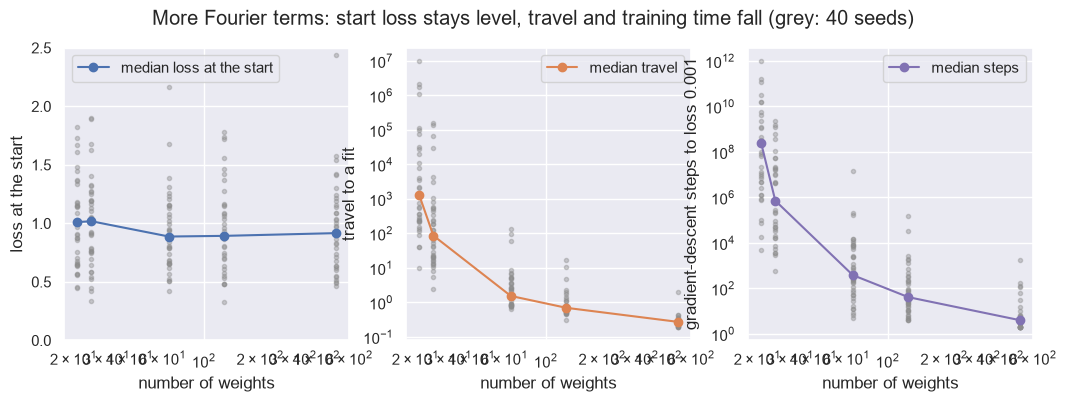

In [7]:
figure, axes = plt.subplots(1, 3, figsize=(12.5, 3.8))
for size in fitting_sizes:
    rows = many_rows[size]
    for axis, key in zip(axes, ("loss", "travel", "steps")):
        axis.plot([size] * len(rows), [row[key] for row in rows], ".", color=BEFORE, alpha=0.4)
for axis, key, color, label in ((axes[0], "loss", NEAREST, "median loss at the start"),
                                (axes[1], "travel", VERTICAL, "median travel"),
                                (axes[2], "steps", MODEL, "median steps")):
    axis.plot(fitting_sizes, [medians[size][key] for size in fitting_sizes], "o-", color=color, label=label)
    axis.set_xscale("log")
    axis.set_xlabel("number of weights")
    axis.legend()
axes[0].set_ylabel("loss at the start")
axes[0].set_ylim(0, 2.5)
axes[1].set_yscale("log")
axes[1].set_ylabel("travel to a fit")
axes[2].set_yscale("log")
axes[2].set_ylabel("gradient-descent steps to loss 0.001")
figure.suptitle("More Fourier terms: start loss stays level, travel and training time fall (grey: 40 seeds)")
save_figure(figure, "09-travel-sweep")
plt.show()